In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath} \usepackage{xfrac}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 11,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'marker': 'o',
                  'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

In [2]:
def plot_spl_coefficients(spl_noise_dict: dict, num_qubits, 
                          figsize = (20, 6), dx = 0.25, alpha = 0.1,
                          rescale_factor = 1e3, labelfontsize = 14,
                          filename = None):
    """
    Plots the coefficients of a Sparse Pauli Lindblad noise in a histogram.

    Args
    -----------
    spl_noise_dict (dict):  dictonary with pauli strings being the keys, and the values being the respective coefficients.
    num_qubits (int):       number of qubits to consider in the SPL noise. If less then the number of qubits in the spl_noise_dict, will
                            select only those Pauli strings and coefficients belonging to qubits [0,..., num_qubits -1]
    dx (float):             width of the colored backround below the histogram. If dx=0, the whole area in the plot will be coloured.
    alpha (float):          transparency of the coloured backround below the histogram bars.
    rescale_factor (float): rescale the coefficients by multiplying them by rescale_factor, and specify it on the y-axis.
    labelfontsize (int):    font size for the x- and y- axes.
    filename (str):         if provided, will save the image in PDF format with this name. 

    Returns
    --------------
    the plot of the SPL coefficients.
    
    """

    def discretize_colormap(cmap, num_colors):
        """
        Given a colormap, outputs a discretized version of the colormap as a list of colors.
        """    
        cmap = [cmap(i) for i in range(cmap.N)]   
        cmap = mpl.colors.LinearSegmentedColormap.from_list('Custom cmap', cmap, num_colors) 
        cmap_list = [cmap(i) for i in range(cmap.N)]
        return cmap_list
    
    ################################
    # EXTRACTING SPL COEFFICIENTS
    ################################
    
    # Create a list to contain Pauli strings in specific order (first single-qubit temrs in lexicographical order, then two-qubit in lexicographical order)
    paulis = np.array([['I',] * num_qubits,] * (3 * num_qubits + 9 * (num_qubits - 1)))

    # Create ordered single-qubit terms
    for q in range(num_qubits):
        paulis[3 * q + 0][q] = 'X'
        paulis[3 * q + 1][q] = 'Y'
        paulis[3 * q + 2][q] = 'Z'

    # Create ordered two-qubit terms
    for q in range(num_qubits - 1):
        paulis[3*num_qubits + 9*q + 0][q:q+2] = ['X', 'X']
        paulis[3*num_qubits + 9*q + 1][q:q+2] = ['X', 'Y']
        paulis[3*num_qubits + 9*q + 2][q:q+2] = ['X', 'Z']
        paulis[3*num_qubits + 9*q + 3][q:q+2] = ['Y', 'X']
        paulis[3*num_qubits + 9*q + 4][q:q+2] = ['Y', 'Y']
        paulis[3*num_qubits + 9*q + 5][q:q+2] = ['Y', 'Z']
        paulis[3*num_qubits + 9*q + 6][q:q+2] = ['Z', 'X']
        paulis[3*num_qubits + 9*q + 7][q:q+2] = ['Z', 'Y']
        paulis[3*num_qubits + 9*q + 8][q:q+2] = ['Z', 'Z']

    # Join lists to create Pauli strings
    paulis = [''.join(p) for p in paulis.tolist()]

    # Select values in the provided dictionary and reorders them according to the standard ordering defined above
    max_num_qubits = len(list(spl_noise_dict.keys())[0])

    # If num_qubits < tot qubits in the SPL dictionary, add identities in the keys to ignore undesired qubits
    trivial_qubits = 'I'*(max_num_qubits - num_qubits)
    
    spl_dict = {}
    for p_str in paulis: 
        try:
            spl_dict[p_str] = spl_noise_dict[p_str + trivial_qubits]
        except KeyError: # If Pauli string is absent, assume corresponding coefficient is 0
            spl_dict[p_str] = 0    
    spl_values = list(spl_dict.values())

    # For plotting purposes, add empty places in the list to separate coefficients belonging to different qubits 
    [spl_values.insert(3 * q + _, 0) for _, q in enumerate(range(1, num_qubits + 1))]

    # For plotting purposes, add empty places in the list to separate coefficients belonging to different pairs of qubits 
    [spl_values.insert(4 * num_qubits + 9 * q + _, 0) for _, q in enumerate(range(1, num_qubits + 1))]
    print(spl_values)

    # Labels in the histogram including empty spaces
    labels = ['X', 'Y', 'Z', ''] * num_qubits + ['X\nX', 'X\nY', 'X\nZ', 'Y\nX', 'Y\nY', 'Y\nZ', 'Z\nX', 'Z\nY', 'Z\nZ', ''] * (num_qubits-1)
    # Actual labels in the histogram
    #labels2 = [r'$\textsf{X}$', 'Y', 'Z'] * num_qubits + ['X\nX', 'X\nY', 'X\nZ', 'Y\nX', 'Y\nY', 'Y\nZ', 'Z\nX', 'Z\nY', 'Z\nZ'] * (num_qubits-1)
    labels2 = [r'$\textsf{X}$', r'$\textsf{Y}$', r'$\textsf{Z}$'] * num_qubits + [r'$\textsf{X}$'+'\n'+r'$\textsf{X}$', r'$\textsf{X}$'+'\n'+r'$\textsf{Y}$', r'$\textsf{X}$'+'\n'+r'$\textsf{Z}$', 
                                                                                  r'$\textsf{Y}$'+'\n'+r'$\textsf{X}$', r'$\textsf{Y}$'+'\n'+r'$\textsf{Y}$', r'$\textsf{Y}$'+'\n'+r'$\textsf{Z}$', 
                                                                                  r'$\textsf{Z}$'+'\n'+r'$\textsf{X}$', r'$\textsf{Z}$'+'\n'+r'$\textsf{Y}$', r'$\textsf{Z}$'+'\n'+r'$\textsf{Z}$',] * (num_qubits-1)

    # Get indices at which the labels are nontrivial (i.e. contain empty data)
    non_trivial_idx = np.where(np.array(labels) != '')[0]
    # Indices for single-qubit terms
    single_qubit_idx = np.array_split(non_trivial_idx[:3*num_qubits], num_qubits)
    # Indices for two-qubit terms
    two_qubit_idx = np.array_split(non_trivial_idx[3*num_qubits:], num_qubits-1)

    #######################
    # PLOTTING HISTOGRAM
    #######################
    if num_qubits < 11:
        cmap_1qubit = sns.color_palette("deep", as_cmap=True)
        cmap_2qubit = sns.color_palette("colorblind", as_cmap=True)
    else:
        cmap_1qubit = discretize_colormap(sns.color_palette("flare", as_cmap=True), num_qubits)
        cmap_2qubit = discretize_colormap(sns.color_palette("crest", as_cmap=True), num_qubits-1)

    fig = plt.figure(figsize=figsize)
    
    # Histogram plot
    spl_values = rescale_factor * np.array(spl_values)
    bars = plt.bar(range(len(spl_values)), spl_values, align='center')

    # ylim of the plot
    ymax =  max(spl_values) + 0.1 * max(spl_values)
    plt.ylim(0, ymax)

    plt.xlim(-1 + dx, len(labels)- 1 - dx)

    # Height at which to draw the annotations for the number of qubits
    y_qubs_annotations = ymax - 0.05 * ymax

    # Set the xticks labels to be the Pauli strings
    plt.xticks(np.where(np.array(labels) != '')[0], labels=labels2, fontsize=8)

    # SINGLE-QUBIT TERMS
    # Change colors to the histogram
    for i, sq in enumerate(single_qubit_idx):
        [bars[q].set_color(cmap_1qubit[i]) for q in sq]

    # Add background shading in the corresponding area
    for q in range(num_qubits):
        plt.axvspan(-1 + 4 * q + dx, -1 + 4 * (q + 1) - dx, facecolor=cmap_1qubit[q], alpha=alpha, zorder=0)

    annotation_circle_size = 8 # num_qubits

    # Add annotation for the number of qubits
    for q in range(num_qubits):
        plt.annotate(f"{q}", (1 + 4 * q, y_qubs_annotations), bbox={"boxstyle" : "circle", "facecolor":"white", "edgecolor":"black"}, size = annotation_circle_size, va='center', ha='center')

    plt.vlines(4 * num_qubits - 1, 0, ymax, ls="--", color='black')

    # TWO-QUBIT TERMS
    # Change colors to the histogram
    for i, sq in enumerate(two_qubit_idx):
        [bars[q].set_color(cmap_2qubit[i]) for q in sq]

    # Add background shading in the corresponding area
    for q in range(num_qubits-1):
        plt.axvspan(4 * num_qubits + 10 * q - 1 + dx, 4 * num_qubits + 10 * (q + 1) - 1 - dx, facecolor=cmap_2qubit[q], alpha=alpha, zorder=0)
    
    # Add annotation for the number of qubits
    for q in range(num_qubits-1):
        plt.annotate(f"{q+0}", (4 * num_qubits + 10 * q + 1.8, y_qubs_annotations), bbox={"boxstyle" : "circle", "facecolor":"white", "edgecolor":"black"}, size = annotation_circle_size, ha='center', va='center')
        plt.annotate(f"{q+1}", (4 * num_qubits + 10 * q + 5.2, y_qubs_annotations), bbox={"boxstyle" : "circle", "facecolor":"white", "edgecolor":"black"}, size = annotation_circle_size, ha='center', va='center')
        plt.plot([4 * num_qubits + 10 * q + 2, 4 * num_qubits + 10 * q + 5], [y_qubs_annotations + ymax*0.002, y_qubs_annotations + ymax*0.002], c = 'black')

    plt.xlabel("Pauli-Lindblad operator", fontsize=14)
    
    if rescale_factor != 1:
        exp = int(np.log10(rescale_factor))
        plt.ylabel(rf"Coefficient ($\times 10^{exp}$)", fontsize=labelfontsize)
    else: 
        plt.ylabel("Value", fontsize=labelfontsize)

    plt.tight_layout()

    if isinstance(filename, str):
        plt.savefig(filename + ".pdf", format="pdf")

[0.0023, 0.00185, 0.00132, 0, 0.0009, 0.0004, 0.00021, 0, 0.00017, 0.00028, 0.00046, 0, 0.00038, 7e-05, 0.00116, 0, 0.00025, 0.00045, 0.0, 0, 0.00041, 0.00026, 0.00012, 0, 0.00065, 0.00047, 0.00212, 0, 0.0009, 0.0, 0.0001, 0, 0.00058, 0.00065, 0.00065, 0, 0.00168, 0.00015, 0.00055, 0, 0.00141, 0.00206, 0.00149, 0, 0.00115, 0.00027, 0.00057, 0, 0.00141, 0.00025, 0.00023, 0, 0.00144, 0.00129, 0.00134, 0, 0.00087, 0.0003, 0.00032, 0, 0.00026, 0.00024, 0.00165, 0, 0.00057, 0.00032, 0.00186, 0, 0.00017, 0.00041, 0.0001, 0, 0.00218, 0.00161, 0.00118, 0, 0.00084, 0.00083, 0.00143, 0, 0.0023, 0.0, 0.0, 0.00185, 0.0, 0.0, 0.00022, 0.0008, 0.00083, 0, 0.00018, 0.0, 0.0, 0.0, 0.00026, 0.00014, 4e-05, 0.00027, 0.0003, 0, 0.00069, 0.00081, 0.00012, 8e-05, 5e-05, 0.00081, 5e-05, 8e-05, 0.00091, 0, 0.00025, 5e-05, 0.0, 0.0, 0.00012, 0.00062, 0.0, 0.0, 0.00364, 0, 0.00051, 0.0, 0.00034, 0.00062, 0.00034, 0.0, 0.0003, 0.00137, 0.00082, 0, 0.00025, 0.0, 0.00027, 0.0, 0.00091, 0.0002, 0.00057, 0.00013, 0

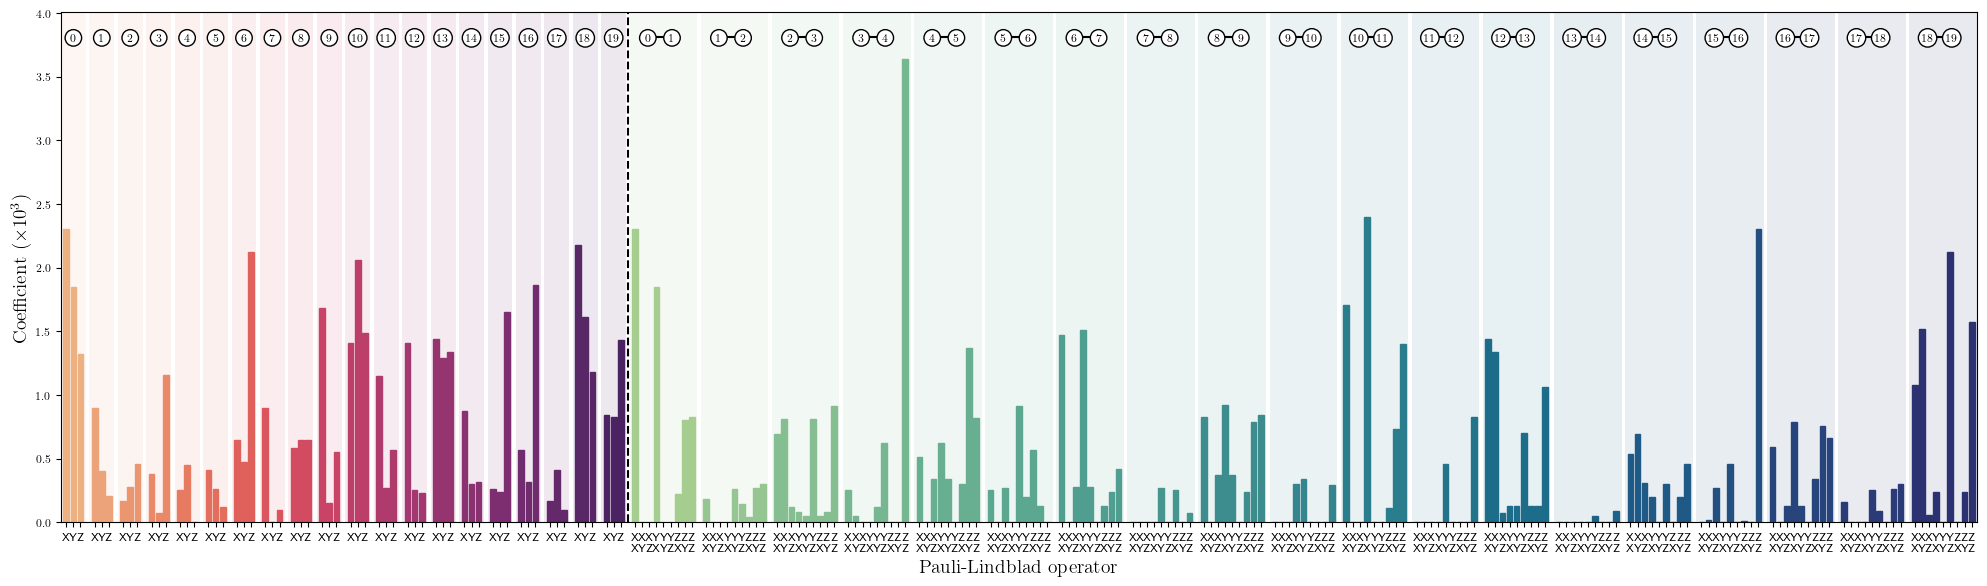

In [15]:
coeffs_file = 'gen_dict_bigger_231127_kyiv_50q'
#coeffs_file = 'ext_gen_dict_bigger_231106_nazca_50q'
#coeffs_file = 'noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s'

with open('../' + coeffs_file + '.json') as file:
    spl_coeffs = json.load(file)

num_qubits = 20
plot_spl_coefficients(spl_coeffs, num_qubits, rescale_factor=1e3, filename = coeffs_file)

### Create txt of coefficients given json

In [ ]:
num_qubits = 50

fname = '../gen_dict_bigger_231127_kyiv_50q'
with open(fname + '.json') as file:
    spl_coeffs = json.load(file)

# Create a list to contain Pauli strings in specific order (first single-qubit temrs in lexicographical order, then two-qubit in lexicographical order)
paulis = np.array([['I',] * num_qubits,] * (3 * num_qubits + 9 * (num_qubits - 1)))

# Create ordered single-qubit terms
for q in range(num_qubits):
    paulis[3 * q + 0][q] = 'X'
    paulis[3 * q + 1][q] = 'Y'
    paulis[3 * q + 2][q] = 'Z'

# Create ordered two-qubit terms
for q in range(num_qubits - 1):
    paulis[3*num_qubits + 9*q + 0][q:q+2] = ['X', 'X']
    paulis[3*num_qubits + 9*q + 1][q:q+2] = ['X', 'Y']
    paulis[3*num_qubits + 9*q + 2][q:q+2] = ['X', 'Z']
    paulis[3*num_qubits + 9*q + 3][q:q+2] = ['Y', 'X']
    paulis[3*num_qubits + 9*q + 4][q:q+2] = ['Y', 'Y']
    paulis[3*num_qubits + 9*q + 5][q:q+2] = ['Y', 'Z']
    paulis[3*num_qubits + 9*q + 6][q:q+2] = ['Z', 'X']
    paulis[3*num_qubits + 9*q + 7][q:q+2] = ['Z', 'Y']
    paulis[3*num_qubits + 9*q + 8][q:q+2] = ['Z', 'Z']

# Join lists to create Pauli strings
paulis = [''.join(p) for p in paulis.tolist()]

max_num_qubits = len(list(spl_coeffs.keys())[0])

# If num_qubits < tot qubits in the SPL dictionary, add identities in the keys to ignore undesired qubits
trivial_qubits = 'I' * (max_num_qubits - num_qubits)

spl_dict = {}
for p_str in paulis: 
    try:
        spl_dict[p_str] = spl_coeffs[p_str + trivial_qubits]
    except KeyError:
        spl_dict[p_str] = 0

spl_values = list(spl_dict.values())

with open(fname + ".txt", "w") as file:
    file.write("pauli,coefficient\n")
    for k, v in spl_dict.items():
        file.write(f"{k},{v}\n")

FileNotFoundError: [Errno 2] No such file or directory: '../vtt_4q_coefffs.json'